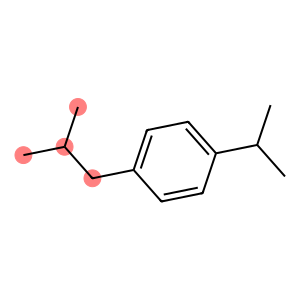

In [15]:
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import rdmolops
from rdkit.Chem import Descriptors
from rdkit.Chem import AllChem

def draw_highlighted_atoms(mol, atom_ids):
    # Create a list of atom indices to highlight
    highlight_atoms = set(atom_ids)

    # Generate image with highlighted atoms
    img = Draw.MolToImage(mol, highlightAtoms=highlight_atoms, size=(300, 300))

    return img

# Example usage
smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(smiles)

# List of atom indices to highlight
atom_ids = [0, 1, 2, 3]

# Draw the molecule with highlighted atoms
highlighted_image = draw_highlighted_atoms(mol, atom_ids)
highlighted_image.show()  # This will display the image

In [16]:
def extract_substructure(mol, atom_ids):
    # Create an empty molecule and add only the atoms of interest
    new_mol = Chem.RWMol()

    # Add atoms that are in the atom_ids list to the new molecule
    atom_map = {}
    for atom_idx in atom_ids:
        atom = mol.GetAtomWithIdx(atom_idx)
        new_atom_idx = new_mol.AddAtom(atom)
        atom_map[atom_idx] = new_atom_idx

    # Now we add the bonds that correspond to the atoms in atom_ids
    for bond in mol.GetBonds():
        idx1 = bond.GetBeginAtomIdx()
        idx2 = bond.GetEndAtomIdx()

        # Check if both atoms are in the atom_ids list, if so, add the bond
        if idx1 in atom_ids and idx2 in atom_ids:
            new_mol.AddBond(atom_map[idx1], atom_map[idx2], bond.GetBondType())
        elif idx1 in atom_ids or idx2 in atom_ids:
            dummy_atm = AllChem.Atom(0)
            if idx1 in atom_ids:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx1], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                #new_mol.GetAtomWithIdx(idx1).SetNumExplicitHs(0)
                #new_mol.GetAtomWithIdx(idx2).SetNoImplicit(False)
            else:
                new_mol.AddAtom(dummy_atm)
                new_mol.AddBond(atom_map[idx2], new_mol.GetNumAtoms() - 1, bond.GetBondType())
                #new_mol.GetAtomWithIdx(idx2).SetNumExplicitHs(0)
                #new_mol.GetAtomWithIdx(2).SetNoImplicit(False)
    
    # Get the substructure as a SMILES string
    #rdmolops.SetAromaticity(new_mol)
    #Chem.SanitizeMol(new_mol, Chem.rdmolops.SanitizeFlags.SANITIZE_ALL)
    new_mol.UpdatePropertyCache()
    mw = Descriptors.ExactMolWt(new_mol)
    #substructure_smiles = Chem.MolToSmiles(new_mol, isomericSmiles=True)
    substructure_smiles = Chem.MolToSmarts(new_mol, isomericSmiles=True)
    print(f"Substructure SMARTS: {substructure_smiles}")
    print(f"Substructure base mass: {mw}")
    return substructure_smiles

Substructure SMARTS: [#6]-[#6](-[#6])-[#6]-[#0]
Substructure base mass: 57.070425287999996


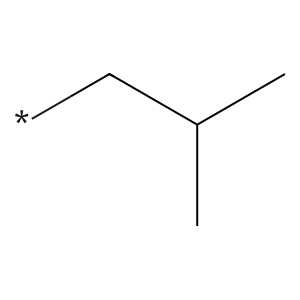

In [ ]:
# Example usage
target_smiles = 'CC(C)CC1=CC=C(C=C1)C(C)C'  # Target molecule
mol = Chem.MolFromSmiles(target_smiles)
# Kekulize the molecule (convert aromatic bonds to single and double bonds)
#Chem.Kekulize(mol, clearAromaticFlags=True)
# Optionally, sanitize the molecule
Chem.SanitizeMol(mol)

# List of atom indices to form the substructure
atom_ids = [0, 1, 2, 3]

# Extract substructure from atom indices
substructure_smiles = extract_substructure(mol, atom_ids)
#print("Substructure SMARTS:", substructure_smiles)
sub_mol = Chem.MolFromSmarts(substructure_smiles)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

Substructure SMARTS: [#6](-[#6](-[#6])-[#6])(=[#0])-[#0]
Substructure base mass: 55.054775224
Substructure SMARTS: [#6](-[#6](-[#6])-[#6])(=[#0])-[#0]


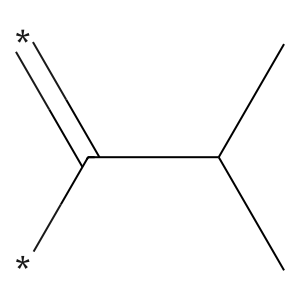

In [18]:
# Extract substructure from atom indices
atom_ids = [7, 10, 11, 12]
substructure_smiles = extract_substructure(mol, atom_ids)
print("Substructure SMARTS:", substructure_smiles)
sub_mol = Chem.MolFromSmarts(substructure_smiles)
img = Draw.MolToImage(sub_mol,  size=(300, 300))
img.show()  # This will display the image of the substructure

In [19]:
def match_substructure(target_smiles, substructure_smiles):
    target_mol = Chem.MolFromSmiles(target_smiles)
    substructure_mol = Chem.MolFromSmiles(substructure_smiles)
    
    # Perform substructure match
    matches = target_mol.GetSubstructMatches(substructure_mol)
    return matches

# Perform substructure match with the target molecule
matches = match_substructure(target_smiles, substructure_smiles)

print("Substructure Matches:", matches)

Substructure Matches: ()


In [20]:
def match_smart_substructure(target_smiles, substructure_smiles):
    target_mol = Chem.MolFromSmiles(target_smiles)
    substructure_mol = Chem.MolFromSmarts(substructure_smiles)
    
    # Perform substructure match
    matches = target_mol.GetSubstructMatches(substructure_mol)
    return matches

# Perform substructure match with the target molecule
matches = match_smart_substructure(target_smiles, substructure_smiles)

print("Substructure Matches:", matches)

Substructure Matches: ()
